# Importing

## Import Library

In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')


# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/stochasticskywalker/indian-agriculture-crop-dataset/agriculture_dataset.xlsx


## Import CSV And convert to DataFrame

In [2]:
df = pd.read_excel('/kaggle/input/datasets/stochasticskywalker/indian-agriculture-crop-dataset/agriculture_dataset.xlsx')

# Preprocessing

## Frist five row

In [3]:
pd.set_option('display.max_columns', None)
df.head()

,S.No,State,District,Season,Crop,Crop_suitability,Previous_crop,Sowing Start,Sowing End,Harvest Days,Soil_type,Soil_pH,organic_carbon,Soil_moisture,N,P,K,Avg_temperature,temperature_min,temperature_max,Avg_humidity,humidity,Rainfall,Rain Probability,Water_availability%,Solar_radiation,solar_radiation,wind_speed,area_hectare,production_tonnes,yield_tonnes_per_ha,Pests,Pesticides,Disease,Risk
0,1,Andhra Pradesh,Srikakulam,Kharif,Paddy,Highly Suitable,Sunnhemp,June 2nd Fortnight,July 2nd Fortnight,135,Red Sandy Loam,6.40,0.6,22,170.0,20.0,210.0,29.8,24.2,36.3,80,82,607.2,81.1,68.4,19.20,5.33,13.2,90312.0,477750.48,5.29,"Yellow Stem Borer (Scirpophaga incertulas), Le...","Chlorantraniliprole 18.5 SC @ 150 ml/ha, Dinot...","Blast (Magnaporthe oryzae), Sheath Blight (Rhi...",Heavy cyclonic rainfall during ripening; veget...
1,2,Andhra Pradesh,Srikakulam,Kharif,Paddy (Early),Highly Suitable,Greengram,June 1st Fortnight,July 1st Fortnight,115,Coastal Alluvium,6.59,0.59,23.1,176.0,23.0,222.0,30.0,24.4,36.3,81.4,83.2,620.4,81.3,69.5,19.67,5.46,13.1,64302.0,331155.30,5.15,"Stem Borer, Gall Midge, Green Leaf Hopper","Cartap Hydrochloride 50 SP @ 1000 g/ha, Fipron...","Brown Spot (Bipolaris oryzae), Bacterial Leaf ...",Early dry spell during tillering stage; lodgin...
2,3,Andhra Pradesh,Srikakulam,Kharif,Cotton,Highly Suitable,Bengalgram,June 2nd Fortnight,July 3rd Week,165,Red Loam,6.70,0.56,24.2,182.0,26.0,234.0,30.3,24.6,36.1,82.5,83.9,633.6,81.5,70.6,20.06,5.57,12.9,51382.0,117664.78,2.29,"Pink Bollworm (Pectinophora gossypiella), Whit...","Profenofos 50 EC @ 1500 ml/ha, Pyriproxyfen 10...","Bacterial Blight (Xanthomonas malvacearum), Gr...",Pink bollworm resistance; square drop due to w...
3,4,Andhra Pradesh,Srikakulam,Kharif,Cotton (Medium),Suitable,Groundnut,July 1st Week,July 4th Week,145,Lateritic Clay Loam,6.66,0.53,25.3,188.0,29.0,246.0,30.4,24.8,36.0,83,83.7,646.8,81.7,71.6,20.32,5.64,12.5,34629.0,74106.06,2.14,"Jassids, Aphids, American Bollworm","Flonicamid 50 WG @ 150 g/ha, Spinetoram 11.7 S...","Alternaria Leaf Spot, Root Rot",Sucking pest resurgence; excessive vegetative ...
4,5,Andhra Pradesh,Srikakulam,Kharif,Groundnut,Highly Suitable,Foxtail Millet,June 3rd Week,July 3rd Week,105,Red Sandy Loam,6.50,0.49,26.4,194.0,32.0,258.0,30.5,24.8,35.7,82.7,82.6,660.0,81.9,72.7,20.40,5.67,12.1,94435.0,125598.55,1.33,"Leaf Miner (Aproaerema modicella), Spodoptera ...","Novaluon 10 EC @ 750 ml/ha, Quinalphos 25 EC @...",Early and Late Tikka Leaf Spot (Cercospora ara...,Mid-season dry spells coinciding with pegging ...


## last Five row

In [4]:
df.tail()

,S.No,State,District,Season,Crop,Crop_suitability,Previous_crop,Sowing Start,Sowing End,Harvest Days,Soil_type,Soil_pH,organic_carbon,Soil_moisture,N,P,K,Avg_temperature,temperature_min,temperature_max,Avg_humidity,humidity,Rainfall,Rain Probability,Water_availability%,Solar_radiation,solar_radiation,wind_speed,area_hectare,production_tonnes,yield_tonnes_per_ha,Pests,Pesticides,Disease,Risk
72321,72322,West Bengal,Purulia,Zaid,Summer Fodder Maize (African Tall),Highly Suitable,Potato,15-Feb,15-Mar,58,Red Gravelly Laterite Soil,6.20,0.36,32.4,113.0,13.0,142.0,27.8,25.7,42.3,44,48.4,94.7,41,27%,25.20,7.00,8.9,2261.60,71828.42,31.76,Fall Armyworm & Stem Borer,Emamectin Benzoate 5% SG @ 200 g/ha or Bacillu...,Banded Leaf Blight,Armyworm defoliation wiping out green forage
72322,72323,West Bengal,Purulia,Zaid,Summer Green Manure / Dhaincha (Sesbania acule...,Highly Suitable,Potato,01-Apr,30-Apr,54,Skeletal Hill Loam,5.62,0.42,18.9,129.0,12.0,149.0,30.8,25.4,43.9,40,39.6,154.4,29,26%,23.40,6.50,8.2,6973.85,143521.83,20.58,Semilooper & Flea Beetle,Neem formulation or Quinalphos 25% EC @ 1.0 L/ha,Collar Rot,Premature drought drying succulent biomass bef...
72323,72324,West Bengal,Purulia,Zaid,Summer Green Manure / Sunnhemp (Crotalaria jun...,Optimal,Mustard,10-Apr,05-May,46,Subarnarekha Headwater Loam,5.82,0.31,36.7,134.0,10.0,173.0,36.3,23.4,42.2,38,49.5,146.1,27,46%,24.47,6.80,8.2,3875.49,58326.12,15.05,Sunnhemp Hairy Caterpillar (Utetheisa pulchella),Malathion 5% Dust @ 25 kg/ha or Neem Oil @ 2.5...,Vascular Wilt (Fusarium udum var. crotalariae),Poor nodulation in acidic coarse soils without...
72324,72325,West Bengal,Purulia,Zaid,Summer Leafy Jute / Pat Saag (JRO 524),Highly Suitable,Mustard,01-Mar,31-Mar,37,Eroded Plateau Red Clay,6.16,0.3,24.1,140.0,11.0,172.0,36.5,24.0,42.4,45,45,76.7,25,37%,23.29,6.47,6.7,5298.93,36456.64,6.88,Flea Beetle & Yellow Mite,Neem Oil 1500 ppm @ 2.5 L/ha or NSKE 5%,Seedling Damping Off,Moisture stress halting quick tender leaf flus...
72325,72326,West Bengal,Purulia,Zaid,Summer Fodder Bajra / Pearl Millet (Giant Bajra),Highly Suitable,Fallow Upland,01-Mar,31-Mar,53,Red Gravelly Laterite Soil,5.36,0.3,30.4,141.0,10.0,157.0,37.8,25.0,42.4,40,39.7,73.5,35,51%,24.33,6.76,10.8,5450.55,208756.07,38.30,Grasshoppers & Stem Borer,Quinalphos 25% EC @ 1.0 L/ha or Neem Oil @ 2.5...,Downy Mildew & Rust,Terminal moisture stress on upper red laterite...


## Shape of our dataset

In [5]:
df.shape

(72326, 35)

## List out all columns

In [6]:
df.columns

Index(['S.No', 'State', 'District', 'Season', 'Crop', 'Crop_suitability',
       'Previous_crop', 'Sowing Start', 'Sowing End', 'Harvest Days',
       'Soil_type', 'Soil_pH', 'organic_carbon', 'Soil_moisture', 'N', 'P',
       'K', 'Avg_temperature', 'temperature_min', 'temperature_max',
       'Avg_humidity', 'humidity', 'Rainfall', 'Rain Probability',
       'Water_availability%', 'Solar_radiation', 'solar_radiation',
       'wind_speed', 'area_hectare', 'production_tonnes',
       'yield_tonnes_per_ha', 'Pests', 'Pesticides', 'Disease', 'Risk'],
      dtype='object')

## Datatype of each columns

In [7]:
df.dtypes

S.No                     int64
State                   object
District                object
Season                  object
Crop                    object
Crop_suitability        object
Previous_crop           object
Sowing Start            object
Sowing End              object
Harvest Days            object
Soil_type               object
Soil_pH                float64
organic_carbon          object
Soil_moisture           object
N                      float64
P                      float64
K                      float64
Avg_temperature        float64
temperature_min        float64
temperature_max        float64
Avg_humidity            object
humidity                object
Rainfall               float64
Rain Probability        object
Water_availability%     object
Solar_radiation        float64
solar_radiation        float64
wind_speed             float64
area_hectare           float64
production_tonnes      float64
yield_tonnes_per_ha    float64
Pests                   object
Pesticid

## Information of all Columns

In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 72326 entries, 0 to 72325
Data columns (total 35 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   S.No                 72326 non-null  int64  
 1   State                72326 non-null  object 
 2   District             72326 non-null  object 
 3   Season               72326 non-null  object 
 4   Crop                 72326 non-null  object 
 5   Crop_suitability     72326 non-null  object 
 6   Previous_crop        72326 non-null  object 
 7   Sowing Start         72326 non-null  object 
 8   Sowing End           72326 non-null  object 
 9   Harvest Days         72326 non-null  object 
 10  Soil_type            72326 non-null  object 
 11  Soil_pH              72326 non-null  float64
 12  organic_carbon       72326 non-null  object 
 13  Soil_moisture        72326 non-null  object 
 14  N                    72326 non-null  float64
 15  P                    72326 non-null 

## Check Null Value

In [9]:
df.isnull().sum()

S.No                   0
State                  0
District               0
Season                 0
Crop                   0
Crop_suitability       0
Previous_crop          0
Sowing Start           0
Sowing End             0
Harvest Days           0
Soil_type              0
Soil_pH                0
organic_carbon         0
Soil_moisture          0
N                      0
P                      0
K                      0
Avg_temperature        0
temperature_min        0
temperature_max        0
Avg_humidity           0
humidity               0
Rainfall               0
Rain Probability       0
Water_availability%    0
Solar_radiation        0
solar_radiation        0
wind_speed             0
area_hectare           0
production_tonnes      0
yield_tonnes_per_ha    0
Pests                  0
Pesticides             0
Disease                0
Risk                   0
dtype: int64

## Check Dupicate Value

In [10]:
df.duplicated().sum()

np.int64(0)

## Summary

In [11]:
df.describe()

,S.No,Soil_pH,N,P,K,Avg_temperature,temperature_min,temperature_max,Rainfall,Solar_radiation,solar_radiation,wind_speed,area_hectare,production_tonnes,yield_tonnes_per_ha
count,72326.000000,72326.000000,72326.000000,72326.000000,72326.000000,72326.000000,72326.000000,72326.000000,72326.000000,72326.000000,72326.000000,72326.000000,72326.000000,7.232600e+04,72326.000000
mean,36163.500000,6.837692,210.697283,19.756315,254.821958,26.125694,18.900737,32.766156,458.890153,19.975141,13.832402,9.114262,16825.589081,1.662921e+05,12.461394
std,20878.862122,1.092568,56.110452,8.495236,83.623725,6.780256,7.168969,6.787126,628.769571,3.126039,7.406172,3.536085,26589.655003,5.525714e+05,15.016193
min,1.000000,3.810000,10.000000,6.000000,10.000000,-10.900000,-21.900000,-1.800000,0.000000,12.000000,3.140000,2.000000,0.060000,0.000000e+00,0.000000
25%,18082.250000,5.790000,180.000000,14.800000,206.800000,20.400000,12.400000,27.600000,40.000000,17.580000,5.940000,6.300000,1728.225000,8.231825e+03,2.010000
50%,36163.500000,7.170000,214.500000,18.200000,251.000000,27.800000,22.100000,32.900000,127.600000,19.800000,16.300000,8.600000,7362.150000,4.351204e+04,6.615000
75%,54244.750000,7.740000,245.000000,22.400000,304.500000,31.400000,24.300000,38.100000,707.500000,22.400000,19.810000,11.600000,20413.000000,1.426605e+05,18.020000
max,72326.000000,8.900000,409.900000,104.000000,535.600000,43.400000,38.100000,47.500000,4588.600000,30.200000,30.200000,25.600000,278474.500000,2.913324e+07,165.000000


# EDA

In [12]:
def show_fig():
    plt.tight_layout()
    plt.show()

plot_no = 1

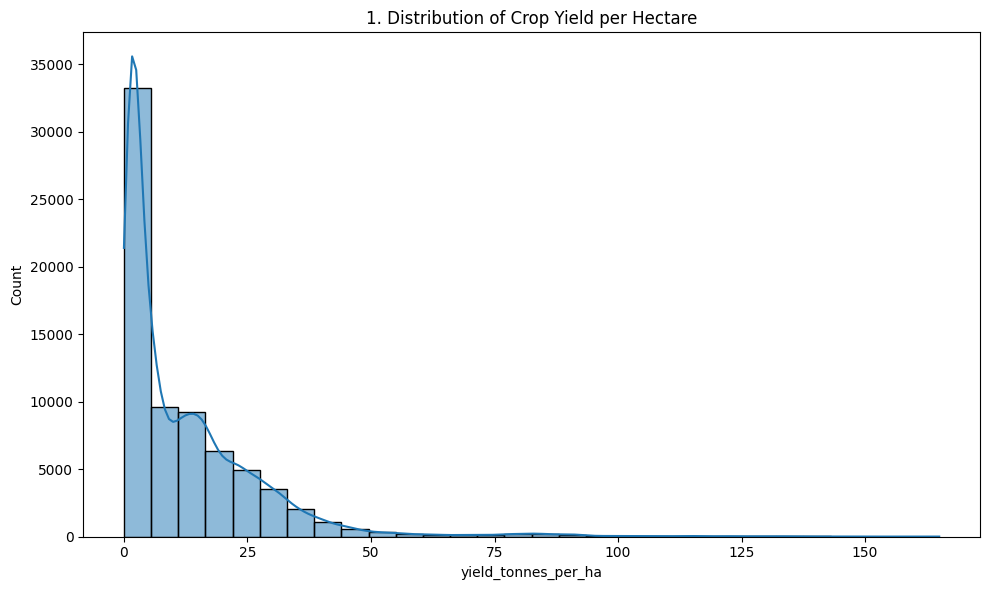

In [13]:
fig = plt.figure(figsize=(10,6))
sns.histplot(data=df, x='yield_tonnes_per_ha', kde=True, bins=30)
plt.title(f'{plot_no}. Distribution of Crop Yield per Hectare')
show_fig()
plot_no += 1

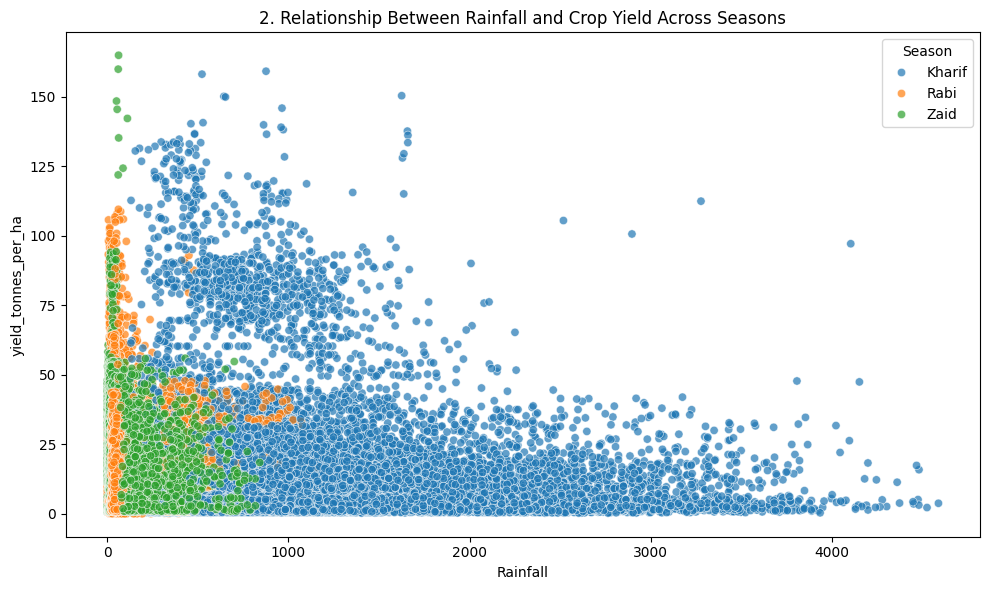

In [14]:
fig = plt.figure(figsize=(10,6))
sns.scatterplot(data=df, x='Rainfall', y='yield_tonnes_per_ha', hue='Season', alpha=0.7)
plt.title(f'{plot_no}. Relationship Between Rainfall and Crop Yield Across Seasons')
show_fig()
plot_no += 1

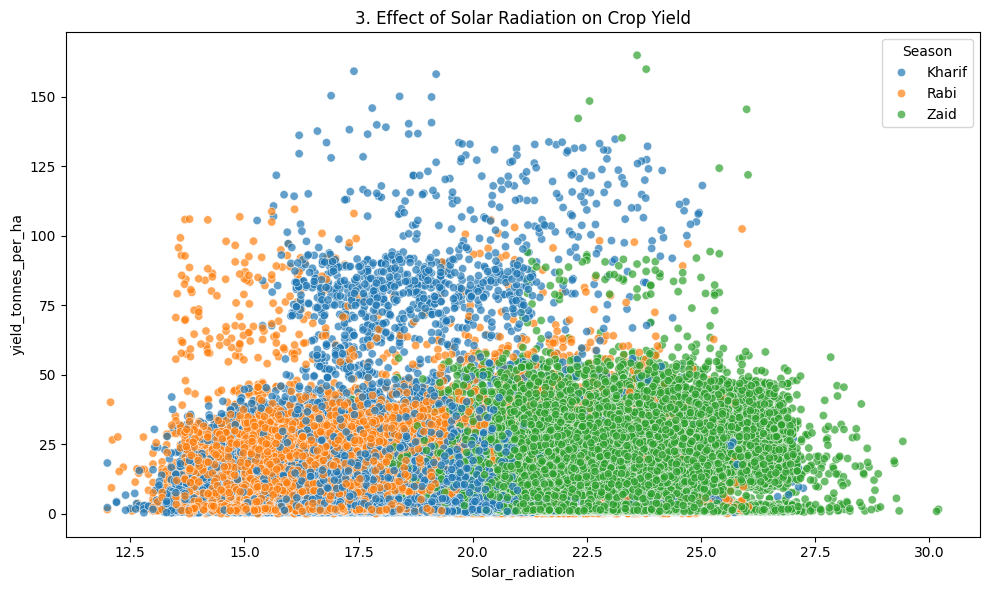

In [15]:
fig = plt.figure(figsize=(10,6))
sns.scatterplot(data=df, x='Solar_radiation', y='yield_tonnes_per_ha', hue='Season', alpha=0.7)
plt.title(f'{plot_no}. Effect of Solar Radiation on Crop Yield')
show_fig()
plot_no += 1

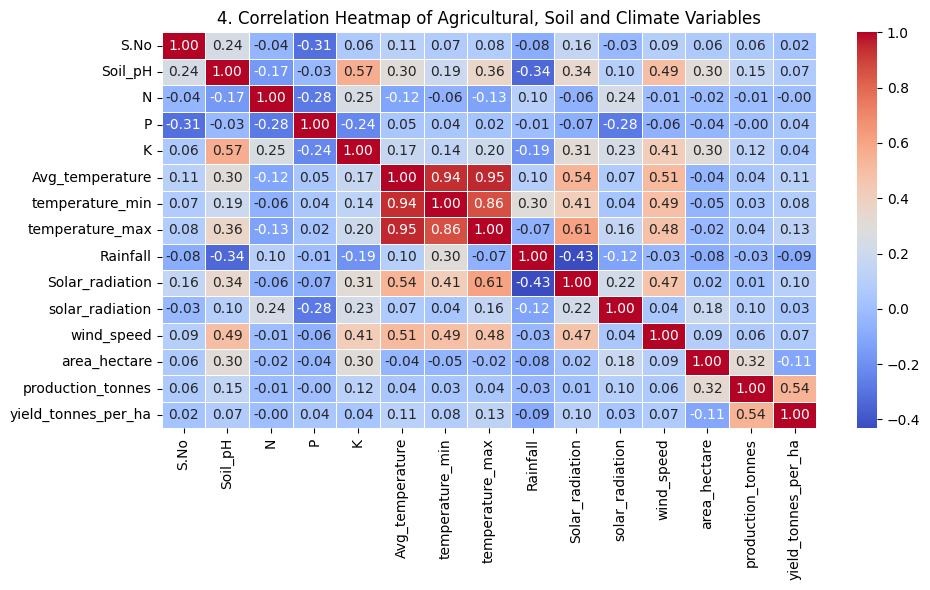

In [16]:
fig = plt.figure(figsize=(10,6))
corr = df.select_dtypes(include='number').corr()
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.title(f'{plot_no}. Correlation Heatmap of Agricultural, Soil and Climate Variables')
show_fig()
plot_no += 1